In [3]:
import h5py
from pynwb import NWBHDF5IO

nwb_path = "/Users/Sam/dc-allen-data-acquire/data/raw/709401-20231213-v001.nwb"

with NWBHDF5IO(nwb_path, "r") as io:
    nwb = io.read()
    tr = nwb.trials.to_dataframe()

with h5py.File("/Users/Sam/dc-allen-data-acquire/code/python/data/probe_samples/709401-20231213-v001_awake.h5", "r") as f:
    t_start = f.attrs["common_start"]
    t_end = f.attrs["window_end_abs"]
    anchor_t = f.attrs["anchor_time_abs"]

stims = tr[(tr.start_time >= t_start) & (tr.start_time < t_end)]
print(f"Awake Window: {t_start:.2f} s  to  {t_end:.2f} s (Anchor / Iso onset at {anchor_t:.2f} s)")
print("Stimulation trial in window:")
print(stims[["start_time", "stop_time"]])
print(f"Time from stim onset to window start: {stims.iloc[0]['start_time'] - t_start:.2f} s")
print(f"Time from stim onset to window end:   {t_end - stims.iloc[0]['start_time']:.2f} s")

Awake Window: 3068.87 s  to  3188.87 s (Anchor / Iso onset at 3193.87 s)
Stimulation trial in window:
     start_time  stop_time
id                        
359  3069.19451  3069.4437
Time from stim onset to window start: 0.33 s
Time from stim onset to window end:   119.67 s


Project root: /Users/Sam/dc-allen-data-acquire/code/python
Sample Rate: 250.0 Hz
Selected LFP: probeF MOs5 (channel index 147)
Selected EEG Frontal: Ch 13 (MOs)
Selected EEG Soma:    Ch 7 (VISa)


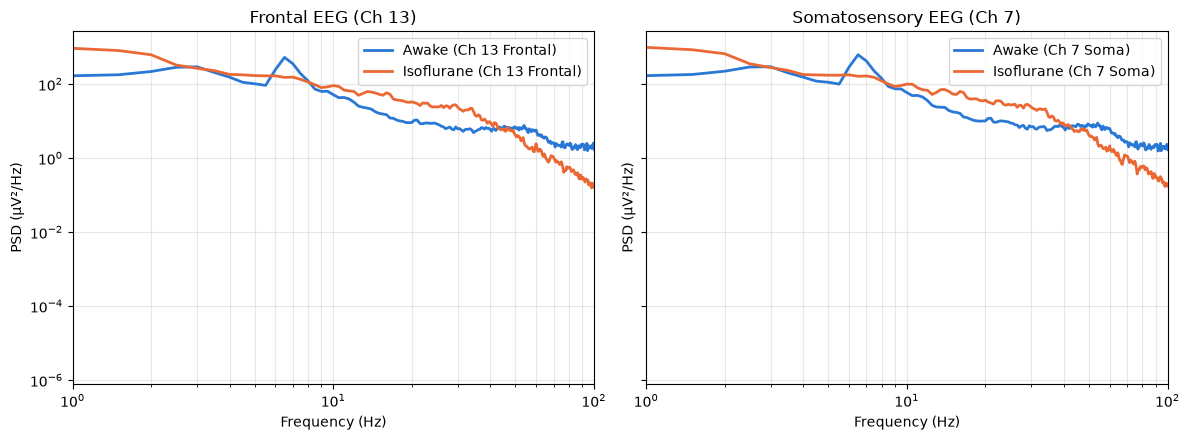

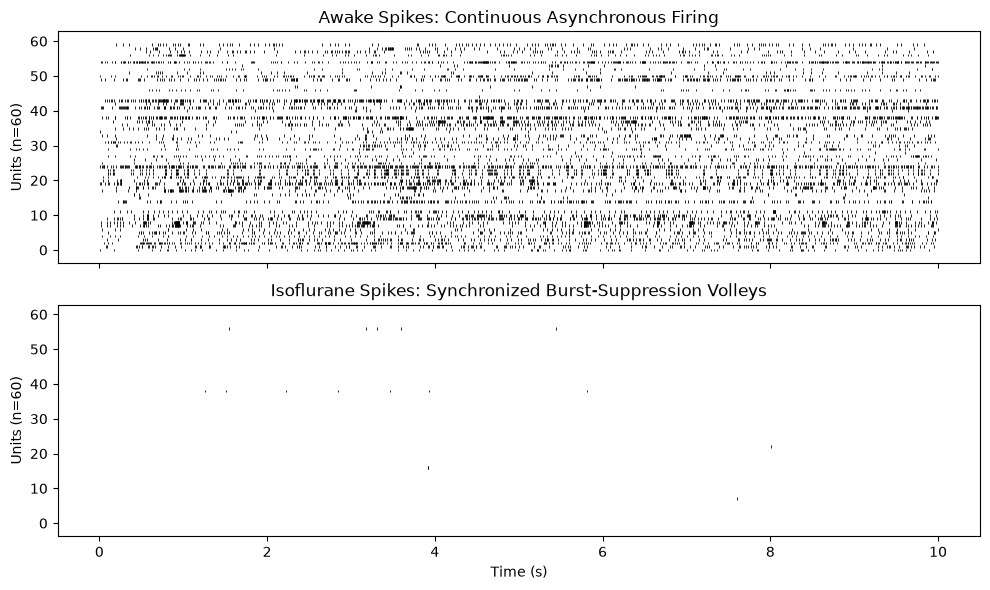


Extracting EEG motifs: Awake
  -> Discovered 1 motif pairs (retained 25001/30001 samples)

Extracting EEG motifs: Isoflurane
  -> Discovered 0 motif pairs (retained 25001/30001 samples)

Extracting EEG motifs: Full/Combined
  -> Discovered 1 motif pairs (retained 55002/60002 samples)


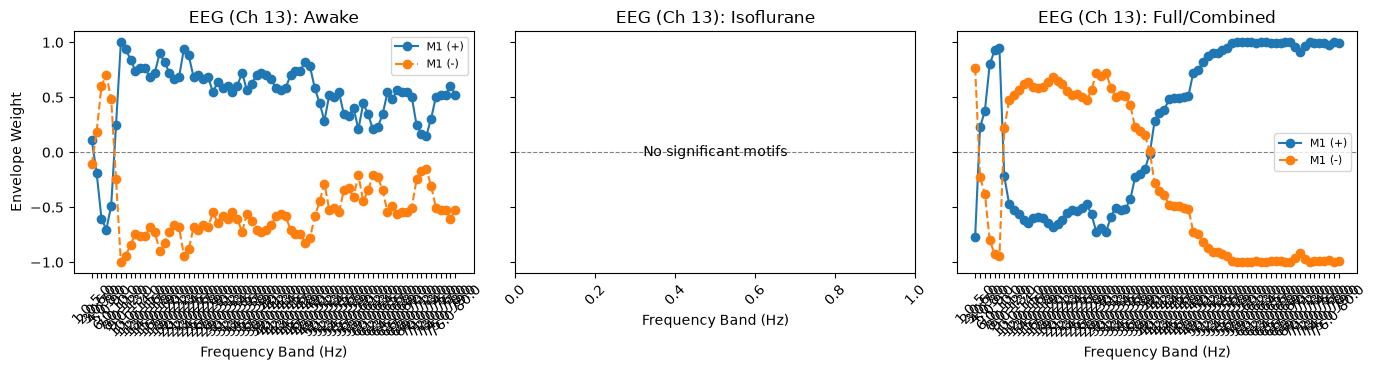


Extracting LFP motifs: Awake
  -> Discovered 1 motif pairs (retained 25001/30001 samples)

Extracting LFP motifs: Isoflurane
  -> Discovered 0 motif pairs (retained 25001/30001 samples)

Extracting LFP motifs: Full/Combined
  -> Discovered 1 motif pairs (retained 55002/60002 samples)


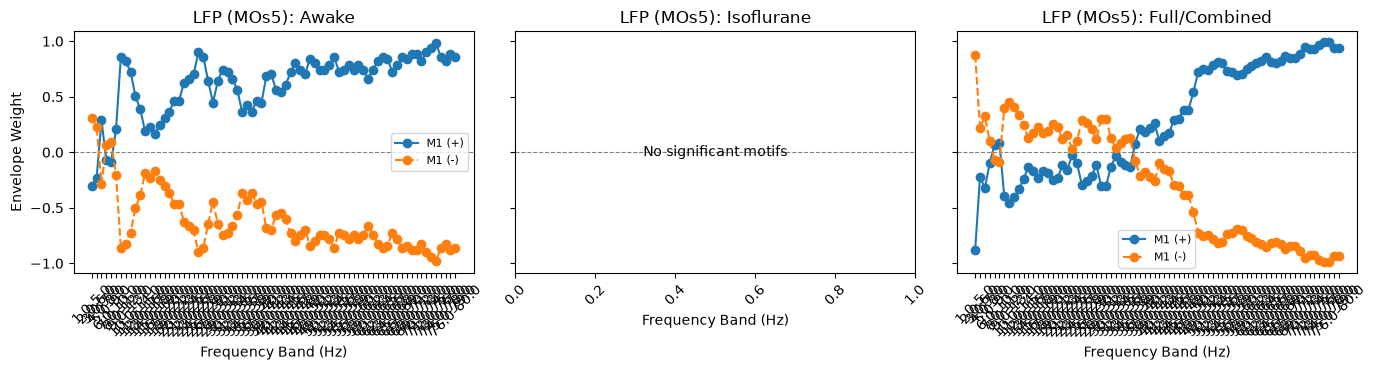

In [1]:
# %% [markdown]
# # Cross-State Electrophysiology: EEG vs. LFP Motifs & Spectra
# Comparing Awake Only, Isoflurane Only, and Full/Combined recording.

# %%
import os
import sys
from pathlib import Path
import h5py
import matplotlib.pyplot as plt
import numpy as np
from pynwb import NWBHDF5IO
from scipy import signal

# -------------------------------------------------------------------------
# PATH ANCHORING
# -------------------------------------------------------------------------
# Walk up directory tree until the root folder containing 'data' is found
curr = Path.cwd().resolve()
root_dir = None
for p in [curr, *curr.parents]:
    if (p / "data").is_dir():
        root_dir = p
        break

if root_dir is None:
    raise FileNotFoundError("Could not find project root containing the 'data' directory.")

# Ensure 'src' is importable
src_parent = root_dir / "code" / "python"
if not (src_parent / "src").is_dir():
    src_parent = root_dir  # fallback if src sits directly under root

if str(src_parent) not in sys.path:
    sys.path.insert(0, str(src_parent))

from src.get_motifs import get_motifs
from src.smooth_env import DEFAULT_FREQ_BANDS, smooth_env

# Configuration paths anchored to project root
DATA_DIR = root_dir / "data" / "probe_samples"
RAW_NWB = root_dir / "data" / "raw" / "709401-20231213-v001.nwb"
SESSION = "709401-20231213-v001"
BANDS = DEFAULT_FREQ_BANDS

# -------------------------------------------------------------------------
# 1. LOAD EXTRACTED 2-MIN WINDOWS (Awake & Isoflurane)
# -------------------------------------------------------------------------
awake_path = DATA_DIR / f"{SESSION}_awake.h5"
iso_path = DATA_DIR / f"{SESSION}_iso_anesthetized.h5"

if not awake_path.exists():
    raise FileNotFoundError(f"Awake file not found: {awake_path}")
if not iso_path.exists():
    raise FileNotFoundError(f"Isoflurane file not found: {iso_path}")

with h5py.File(awake_path, "r") as fa:
    fs = float(fa.attrs["fs"])
    awake_eeg = fa["eeg/data"][:]
    awake_lfp = fa["lfp/data"][:]
    eeg_locs = fa["eeg/location"][:].astype(str)
    lfp_locs = fa["lfp/location"][:].astype(str)
    lfp_probes = fa["lfp/probe"][:].astype(str)
    awake_spikes = {
        "times": fa["spikes/times"][:],
        "index": fa["spikes/index"][:],
        "location": fa["spikes/location"][:].astype(str),
        "y": fa["spikes/y"][:],
    }

with h5py.File(iso_path, "r") as fi:
    iso_eeg = fi["eeg/data"][:]
    iso_lfp = fi["lfp/data"][:]
    iso_spikes = {
        "times": fi["spikes/times"][:],
        "index": fi["spikes/index"][:],
        "location": fi["spikes/location"][:].astype(str),
        "y": fi["spikes/y"][:],
    }

# -------------------------------------------------------------------------
# 2. CHANNEL SELECTION (EEG & Deep LFP)
# -------------------------------------------------------------------------
# Frontal EEG = Channel 13; Somatosensory EEG = Channel 7
eeg_frontal_idx = 13
eeg_soma_idx = 7

# Deep LFP: Target MOs5 or MOs6a on probeF
lfp_match = np.where((lfp_locs == "MOs5") & (lfp_probes == "probeF"))[0]
if len(lfp_match) == 0:
    lfp_match = np.where((lfp_locs == "MOs6a") & (lfp_probes == "probeF"))[0]
if len(lfp_match) == 0:
    # Fallback to any probeF channel starting with MOs
    lfp_match = np.where([loc.startswith("MOs") and p == "probeF" for loc, p in zip(lfp_locs, lfp_probes)])[0]

lfp_deep_idx = lfp_match[0]
print(f"Project root: {root_dir}")
print(f"Sample Rate: {fs} Hz")
print(f"Selected LFP: {lfp_probes[lfp_deep_idx]} {lfp_locs[lfp_deep_idx]} (channel index {lfp_deep_idx})")
print(f"Selected EEG Frontal: Ch {eeg_frontal_idx} ({eeg_locs[eeg_frontal_idx]})")
print(f"Selected EEG Soma:    Ch {eeg_soma_idx} ({eeg_locs[eeg_soma_idx]})")

# Signal dictionaries across states
sig_eeg = {
    "Awake": awake_eeg[:, eeg_frontal_idx],
    "Isoflurane": iso_eeg[:, eeg_frontal_idx],
    "Full/Combined": np.concatenate([awake_eeg[:, eeg_frontal_idx], iso_eeg[:, eeg_frontal_idx]]),
}

sig_lfp = {
    "Awake": awake_lfp[:, lfp_deep_idx],
    "Isoflurane": iso_lfp[:, lfp_deep_idx],
    "Full/Combined": np.concatenate([awake_lfp[:, lfp_deep_idx], iso_lfp[:, lfp_deep_idx]]),
}

# %% [markdown]
# ## 1. Power Spectrum Analysis (EEG & LFP)
# Welch PSD across states for Frontal EEG Ch 13 and Somatosensory Ch 7.

# %%
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for name, col in zip(["Awake", "Isoflurane"], ["#2a78d6", "#eb6834"]):
    data = awake_eeg if name == "Awake" else iso_eeg

    # Frontal (Ch 13)
    f_fr, p_fr = signal.welch(data[:, eeg_frontal_idx], fs=fs, nperseg=int(2 * fs))
    axes[0].plot(
        f_fr, p_fr, color=col, lw=2, label=f"{name} (Ch 13 Frontal)"
    )

    # Somatosensory (Ch 7)
    f_so, p_so = signal.welch(data[:, eeg_soma_idx], fs=fs, nperseg=int(2 * fs))
    axes[1].plot(
        f_so, p_so, color=col, lw=2, label=f"{name} (Ch 7 Soma)"
    )

for ax, title in zip(
    axes, ["Frontal EEG (Ch 13)", "Somatosensory EEG (Ch 7)"]
):
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1, 100)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (µV²/Hz)")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

# %% [markdown]
# ## 2. Spike Raster Plots (LFP / Spikes)
# Compare unit firing synchrony during Awake vs. Isoflurane burst-suppression.

# %%
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)


def plot_raster(ax, spike_dict, title, max_dur=10.0):
    starts = np.concatenate([[0], spike_dict["index"][:-1]])
    trains = []
    n_units = min(len(spike_dict["index"]), 60)
    for r in range(n_units):
        st = spike_dict["times"][starts[r] : spike_dict["index"][r]]
        trains.append(st[(st >= 0) & (st < max_dur)])
    ax.eventplot(trains, colors="black", linewidths=0.6, linelengths=0.8)
    ax.set_title(title)
    ax.set_ylabel(f"Units (n={n_units})")


plot_raster(axes[0], awake_spikes, "Awake Spikes: Continuous Asynchronous Firing")
plot_raster(
    axes[1],
    iso_spikes,
    "Isoflurane Spikes: Synchronized Burst-Suppression Volleys",
)
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 3. EEG Motif Discovery (Ch 13 Frontal)
# Running smooth_env + get_motifs on: Awake only, Iso only, and Combined.

# %%
eeg_motifs = {}
band_names = [f"{lo}-{hi}" for lo, hi in BANDS]

for state, x in sig_eeg.items():
    print(f"\nExtracting EEG motifs: {state}")
    env = smooth_env(x, fs, BANDS)

    #dimension check
    if env.shape[0] > env.shape[1]:
        env = env.T
    
    # Trim NaN edges produced by smooth_env filtering
    valid_cols = np.all(np.isfinite(env), axis=0)
    env_clean = env[:, valid_cols]
    
    res = get_motifs([env_clean], fs, n_null=20, seed=0, verbose=False)
    eeg_motifs[state] = res
    print(f"  -> Discovered {res.n_motifs} motif pairs (retained {env_clean.shape[1]}/{env.shape[1]} samples)")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (state, res) in zip(axes, eeg_motifs.items()):
    ax.axhline(0, color="gray", lw=0.8, ls="--")
    if res.n_motifs > 0:
        for i in range(res.n_motifs):
            ax.plot(band_names, res.motifs[:, i], "-o", label=f"M{i+1} (+)")
            ax.plot(band_names, res.motifs[:, i + res.n_motifs], "--o", label=f"M{i+1} (-)")
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, "No significant motifs", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"EEG (Ch 13): {state}")
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlabel("Frequency Band (Hz)")

axes[0].set_ylabel("Envelope Weight")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## 4. LFP Motif Discovery (Deep MOs)
# Running smooth_env + get_motifs on: Awake only, Iso only, and Combined.

# %%
lfp_motifs = {}

for state, x in sig_lfp.items():
    print(f"\nExtracting LFP motifs: {state}")
    env = smooth_env(x, fs, BANDS)
    
    #dimension check
    if env.shape[0] > env.shape[1]:
        env = env.T
    
    # Trim NaN edges produced by smooth_env filtering
    valid_cols = np.all(np.isfinite(env), axis=0)
    env_clean = env[:, valid_cols]
    
    res = get_motifs([env_clean], fs, n_null=20, seed=0, verbose=False)
    lfp_motifs[state] = res
    print(f"  -> Discovered {res.n_motifs} motif pairs (retained {env_clean.shape[1]}/{env.shape[1]} samples)")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (state, res) in zip(axes, lfp_motifs.items()):
    ax.axhline(0, color="gray", lw=0.8, ls="--")
    if res.n_motifs > 0:
        for i in range(res.n_motifs):
            ax.plot(band_names, res.motifs[:, i], "-o", label=f"M{i+1} (+)")
            ax.plot(band_names, res.motifs[:, i + res.n_motifs], "--o", label=f"M{i+1} (-)")
        ax.legend(fontsize=8)
    else:
        ax.text(0.5, 0.5, "No significant motifs", ha="center", va="center", transform=ax.transAxes)
    ax.set_title(f"LFP ({lfp_locs[lfp_deep_idx]}): {state}")
    ax.tick_params(axis="x", rotation=45)
    ax.set_xlabel("Frequency Band (Hz)")

axes[0].set_ylabel("Envelope Weight")
plt.tight_layout()
plt.show()

In [ ]:
### The motifs kind of look similar!!!